# CNN → MLP 影像分類（PyTorch 實作 + 真的訓練出一個會辨識的模型）

把 `Conv → ReLU → Pool → Conv → ReLU → Pool → Flatten → Linear → ReLU → Linear`
這條流程完整實作出來，並且**真的拿 torchvision 內建的資料集訓練，最後丟圖片進去辨識**。

| 部分 | 內容 |
|---|---|
| 第 1 部分 | 用 `(4, 3, 224, 224)` 假輸入逐層驗證形狀與參數量，對照架構表 |
| 第 2 部分 | 同一個架構接真實資料集 **Imagenette**（10 類真實照片），訓練 → 評估 → 單張圖推論 |

**資料集：`torchvision.datasets.Imagenette`**（ImageNet 挑出來的 10 類，9469 張訓練 / 3925 張驗證，彩色真實照片）。
選它而不是 CIFAR-10 的原因：CIFAR 只有 32×32，而這個架構的說明是針對 224×224 的照片；
Imagenette 的 160px 版本縮到 128×128 訓練，既是真實照片、又能在筆電上幾分鐘跑完。

**輸入尺寸為什麼不用 224**：224×224 在這個架構下 Flatten 會變成 200,704 維，
第一層 Linear 就吃掉 5,138 萬參數（佔全模型 98%），在 MPS/CPU 上訓練不現實。
架構一行都不改，只把輸入換成 128×128，Flatten 後是 64×32×32 = 65,536 維。

## 0. 環境與 device

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.datasets import Imagenette
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# 讓 matplotlib 畫得出中文
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang HK", "Heiti TC", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(0)
np.random.seed(0)

# Apple Silicon -> mps，NVIDIA -> cuda，都沒有 -> cpu
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("device      :", device)

torch       : 2.10.0
torchvision : 0.25.0
device      : mps


---
# 第 1 部分：逐層形狀驗證（224×224）

先把架構表用程式跑一遍，確認每層輸出形狀與參數量真的對得上。

卷積輸出尺寸公式：

$$O = \left\lfloor \frac{I + 2P - K}{S} \right\rfloor + 1$$

Conv1：$I=224,\ P=1,\ K=3,\ S=1 \Rightarrow O = (224+2-3)/1 + 1 = 224$（padding=1 讓長寬不變）

In [2]:
# 完全照架構說明堆出來（輸入 224x224、10 類）
demo = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),   # (3*3*3 + 1) * 32 = 896
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),                  # stride 預設 = kernel_size = 2
    nn.Conv2d(32, 64, kernel_size=3, padding=1),  # (3*3*32 + 1) * 64 = 18496
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Flatten(),                                 # 64 * 56 * 56 = 200704
    nn.Linear(200704, 256),                       # 200704*256 + 256 = 51380480
    nn.ReLU(),
    nn.Linear(256, 10),                           # 256*10 + 10 = 2570
)

x = torch.randn(4, 3, 224, 224)   # N=4(batch), C=3(RGB), H=W=224

print(f"{'step':<14}{'output shape':<26}{'params':>12}")
print("-" * 52)
print(f"{'input':<14}{str(tuple(x.shape)):<26}{'-':>12}")
h = x
for layer in demo:
    h = layer(h)
    n_param = sum(p.numel() for p in layer.parameters())
    print(f"{layer.__class__.__name__:<14}{str(tuple(h.shape)):<26}{(f'{n_param:,}' if n_param else '-'):>12}")
print("-" * 52)
total = sum(p.numel() for p in demo.parameters())
print(f"{'TOTAL':<14}{'(logits)':<26}{total:>12,}")

probs = F.softmax(h, dim=1)          # logits -> 機率
print("\nsoftmax 形狀:", tuple(probs.shape), " 每列總和:", probs.sum(1).detach().numpy().round(4))

step          output shape                    params
----------------------------------------------------
input         (4, 3, 224, 224)                     -
Conv2d        (4, 32, 224, 224)                  896
ReLU          (4, 32, 224, 224)                    -
MaxPool2d     (4, 32, 112, 112)                    -
Conv2d        (4, 64, 112, 112)               18,496
ReLU          (4, 64, 112, 112)                    -
MaxPool2d     (4, 64, 56, 56)                      -
Flatten       (4, 200704)                          -
Linear        (4, 256)                    51,380,480
ReLU          (4, 256)                             -
Linear        (4, 10)                          2,570
----------------------------------------------------
TOTAL         (logits)                    51,402,442

softmax 形狀: (4, 10)  每列總和: [1. 1. 1. 1.]


In [3]:
# 參數幾乎全壓在 Flatten 後的第一層 Linear —— 這是這個架構最大的弱點
for name, m in [("Conv1", demo[0]), ("Conv2", demo[3]), ("Linear1", demo[7]), ("Linear2", demo[9])]:
    n = sum(p.numel() for p in m.parameters())
    print(f"{name:<9}{n:>14,}   {n / total * 100:5.2f}%")

Conv1               896    0.00%
Conv2            18,496    0.04%
Linear1      51,380,480   99.96%
Linear2           2,570    0.00%


---
# 第 2 部分：真的訓練

## 2.1 資料集（torchvision 內建）

`Imagenette(root, split, size='160px', download=True)` 第一次會自己下載解壓（約 99MB），之後直接讀本機。

- train 9469 張 / val 3925 張，彩色，長寬不一（短邊 160）
- 10 類：丁鱥魚、英國史賓格犬、卡式隨身聽、鏈鋸、教堂、法國號、垃圾車、加油槍、高爾夫球、降落傘

transform 的兩個責任：**統一尺寸**（模型的 Linear 層固定了 Flatten 維度，輸入尺寸不能變）
與 **augmentation**（訓練集隨機裁切 + 水平翻轉壓過擬合；驗證集只做 Resize + CenterCrop）。
Normalize 用 ImageNet 的均值/標準差。

In [4]:
DATA_DIR = "./data"   # 資料集放這裡，重跑不用重新下載
IMG_SIZE = 128

MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),                  # PIL (H,W,C) 0~255 -> tensor (C,H,W) 0~1
    transforms.Normalize(MEAN, STD),
])
val_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_set = Imagenette(DATA_DIR, split="train", size="160px", download=True, transform=train_tf)
val_set   = Imagenette(DATA_DIR, split="val",   size="160px", transform=val_tf)

CLASSES = [c[0] for c in train_set.classes]
CLASSES_ZH = ["丁鱥魚", "史賓格犬", "卡式隨身聽", "鏈鋸", "教堂",
              "法國號", "垃圾車", "加油槍", "高爾夫球", "降落傘"]
NUM_CLASSES = len(CLASSES)

train_loader = DataLoader(train_set, batch_size=64,  shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_set,   batch_size=128, shuffle=False, num_workers=0)

print("train:", len(train_set), " val:", len(val_set), " classes:", NUM_CLASSES)
for i, (en, zh) in enumerate(zip(CLASSES, CLASSES_ZH)):
    print(f"  {i}  {en:<18}{zh}")

xb, yb = next(iter(train_loader))
print("\none batch:", tuple(xb.shape), xb.dtype, " labels:", tuple(yb.shape))

train: 9469  val: 3925  classes: 10
  0  tench             丁鱥魚
  1  English springer  史賓格犬
  2  cassette player   卡式隨身聽
  3  chain saw         鏈鋸
  4  church            教堂
  5  French horn       法國號
  6  garbage truck     垃圾車
  7  gas pump          加油槍
  8  golf ball         高爾夫球
  9  parachute         降落傘

one batch: (64, 3, 128, 128) torch.float32  labels: (64,)


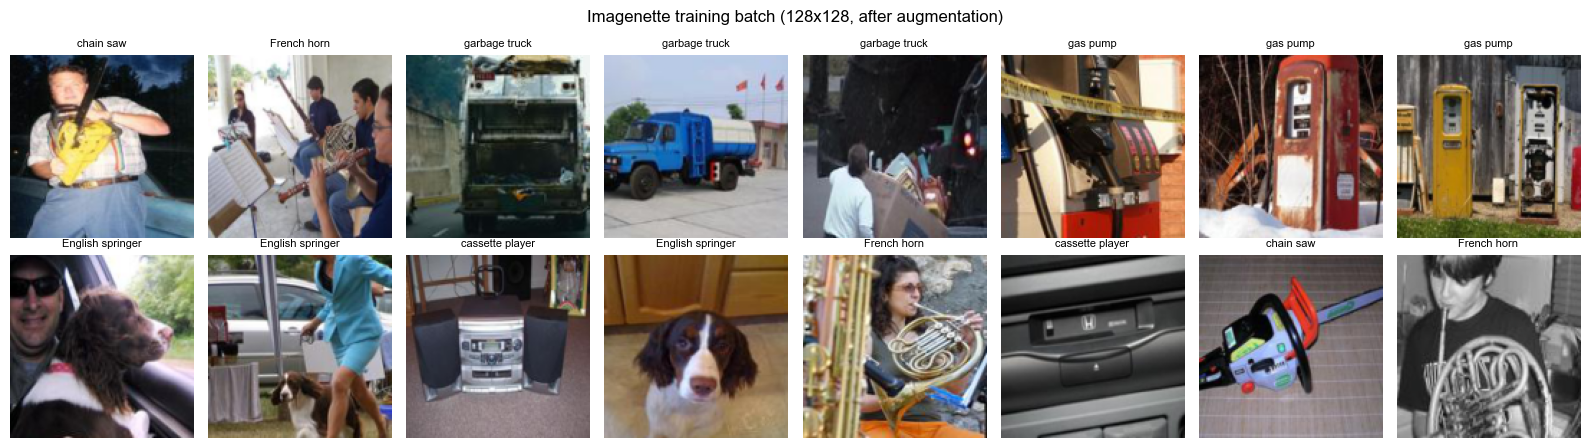

In [5]:
# 看一下實際圖片（要反 normalize 回來才看得懂）
def denorm(t):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, img, lab in zip(axes.ravel(), xb, yb):
    ax.imshow(denorm(img).permute(1, 2, 0).numpy())
    ax.set_title(CLASSES[lab], fontsize=8)
    ax.axis("off")
fig.suptitle("Imagenette training batch (128x128, after augmentation)")
plt.tight_layout(); plt.show()

## 2.2 模型

和第 1 部分**同一個架構**，只是寫成 class 並把輸入尺寸參數化：

```
features   : Conv(3→32,k3,p1) → ReLU → MaxPool2 → Conv(32→64,k3,p1) → ReLU → MaxPool2
flatten    : (N,64,S/4,S/4) → (N, 64*(S/4)^2)
classifier : Linear(→256) → ReLU → Linear(256→10)
```

128×128 的形狀變化：
`(N,3,128,128) → (N,32,128,128) → (N,32,64,64) → (N,64,64,64) → (N,64,32,32) → (N,65536) → (N,256) → (N,10)`

In [6]:
class CNN_MLP(nn.Module):
    # 兩段 Conv→ReLU→Pool 抽特徵，Flatten 之後交給 MLP 做分類
    def __init__(self, in_channels=3, img_size=128, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),   # 長寬不變
            nn.ReLU(),
            nn.MaxPool2d(2),                                        # 長寬減半
            nn.Conv2d(32, 64, kernel_size=3, padding=1),            # 通道 32→64，學更複雜特徵
            nn.ReLU(),
            nn.MaxPool2d(2),                                        # 再減半
        )
        self.flatten = nn.Flatten()                                 # CNN 與 MLP 的交界
        side = img_size // 4                                        # 兩次 MaxPool(2)
        self.flat_dim = 64 * side * side
        self.classifier = nn.Sequential(
            nn.Linear(self.flat_dim, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        return self.classifier(x)        # 回傳 logits，softmax 交給 loss 做


model = CNN_MLP(img_size=IMG_SIZE, num_classes=NUM_CLASSES).to(device)
print(model)
print("\nflatten dim :", f"{model.flat_dim:,}")
print("params      :", f"{sum(p.numel() for p in model.parameters()):,}")

with torch.no_grad():
    print("forward test:", tuple(model(xb[:4].to(device)).shape))

CNN_MLP(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=65536, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)

flatten dim : 65,536
params      : 16,799,434
forward test: (4, 10)


## 2.3 訓練

- loss：`CrossEntropyLoss`（內部含 log-softmax，所以模型輸出直接丟 logits，不要自己先 softmax）
- optimizer：Adam, lr=1e-3，weight_decay=1e-4
- scheduler：cosine 退火，後段自動把學習率壓下來

每個 epoch 做一次完整的 train + validation，並記錄下來畫曲線。

In [7]:
EPOCHS = 12

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


@torch.no_grad()
def evaluate(net, loader):
    net.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = net(xb)
        loss_sum += criterion(logits, yb).item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        n += yb.size(0)
    return loss_sum / n, correct / n


hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc, BEST = 0.0, "checkpoints/cnn_imagenette_best.pt"

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0 = time.time()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)              # (N, 10) logits
        loss = criterion(logits, yb)
        loss.backward()                 # 反向傳播
        optimizer.step()                # 更新權重

        loss_sum += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        n += yb.size(0)

    scheduler.step()
    tr_loss, tr_acc = loss_sum / n, correct / n
    va_loss, va_acc = evaluate(model, val_loader)
    for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]):
        hist[k].append(v)

    if va_acc > best_acc:               # 留下驗證表現最好的那版權重
        best_acc = va_acc
        torch.save(model.state_dict(), BEST)

    print(f"epoch {epoch:2d}/{EPOCHS}  "
          f"train loss {tr_loss:.4f} acc {tr_acc*100:5.2f}%  |  "
          f"val loss {va_loss:.4f} acc {va_acc*100:5.2f}%  "
          f"({time.time()-t0:5.1f}s, lr={scheduler.get_last_lr()[0]:.2e})"
          + ("  <- best" if va_acc == best_acc else ""))

model.load_state_dict(torch.load(BEST, map_location=device))
print(f"\n最佳驗證準確率：{best_acc*100:.2f}%（隨機猜 = {100/NUM_CLASSES:.0f}%）")

epoch  1/12  train loss 1.9866 acc 33.10%  |  val loss 1.6589 acc 43.18%  (184.1s, lr=9.83e-04)  <- best
epoch  2/12  train loss 1.5364 acc 48.75%  |  val loss 1.4513 acc 51.64%  ( 81.6s, lr=9.33e-04)  <- best
epoch  3/12  train loss 1.3890 acc 54.05%  |  val loss 1.3725 acc 53.78%  ( 48.7s, lr=8.54e-04)  <- best
epoch  4/12  train loss 1.2677 acc 57.56%  |  val loss 1.2010 acc 61.07%  ( 47.3s, lr=7.50e-04)  <- best
epoch  5/12  train loss 1.1721 acc 60.80%  |  val loss 1.2888 acc 58.42%  ( 46.5s, lr=6.29e-04)
epoch  6/12  train loss 1.0842 acc 63.98%  |  val loss 1.1039 acc 64.10%  ( 46.3s, lr=5.00e-04)  <- best
epoch  7/12  train loss 1.0087 acc 67.00%  |  val loss 1.0249 acc 66.55%  ( 43.6s, lr=3.71e-04)  <- best
epoch  8/12  train loss 0.9549 acc 69.10%  |  val loss 0.9932 acc 67.85%  ( 43.0s, lr=2.50e-04)  <- best
epoch  9/12  train loss 0.9058 acc 70.24%  |  val loss 0.9721 acc 68.59%  ( 41.5s, lr=1.46e-04)  <- best
epoch 10/12  train loss 0.8577 acc 72.05%  |  val loss 0.9625 ac

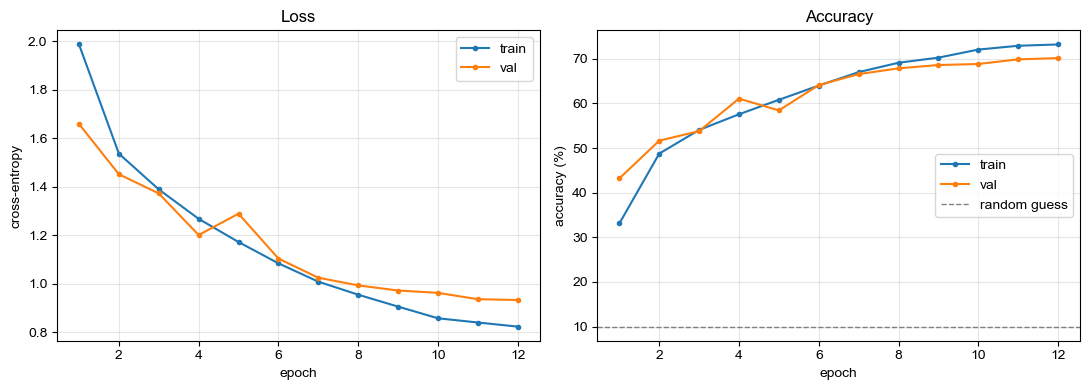

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ep = range(1, len(hist["train_loss"]) + 1)
ax1.plot(ep, hist["train_loss"], "-o", ms=3, label="train")
ax1.plot(ep, hist["val_loss"], "-o", ms=3, label="val")
ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy"); ax1.set_title("Loss"); ax1.legend(); ax1.grid(alpha=.3)

ax2.plot(ep, [a*100 for a in hist["train_acc"]], "-o", ms=3, label="train")
ax2.plot(ep, [a*100 for a in hist["val_acc"]], "-o", ms=3, label="val")
ax2.axhline(100/NUM_CLASSES, ls="--", c="gray", lw=1, label="random guess")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy (%)"); ax2.set_title("Accuracy"); ax2.legend(); ax2.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 2.4 評估：每類準確率 + confusion matrix

In [9]:
model.eval()
preds, trues, probs_all = [], [], []
with torch.no_grad():
    for xb, yb in val_loader:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs_all.append(p); preds.append(p.argmax(1)); trues.append(yb)
y_pred = torch.cat(preds).numpy()
y_true = torch.cat(trues).numpy()
y_prob = torch.cat(probs_all).numpy()

print(f"overall accuracy: {(y_pred == y_true).mean()*100:.2f}%\n")
print(f"{'class':<18}{'zh':<12}{'acc':>8}{'support':>9}")
print("-" * 48)
for i, (en, zh) in enumerate(zip(CLASSES, CLASSES_ZH)):
    m = y_true == i
    print(f"{en:<18}{zh:<12}{(y_pred[m] == i).mean()*100:7.2f}%{m.sum():9d}")

overall accuracy: 70.14%

class             zh               acc  support
------------------------------------------------
tench             丁鱥魚           82.69%      387
English springer  史賓格犬          77.47%      395
cassette player   卡式隨身聽         73.11%      357
chain saw         鏈鋸            47.41%      386
church            教堂            70.90%      409
French horn       法國號           69.54%      394
garbage truck     垃圾車           76.61%      389
gas pump          加油槍           66.35%      419
golf ball         高爾夫球          60.90%      399
parachute         降落傘           76.92%      390


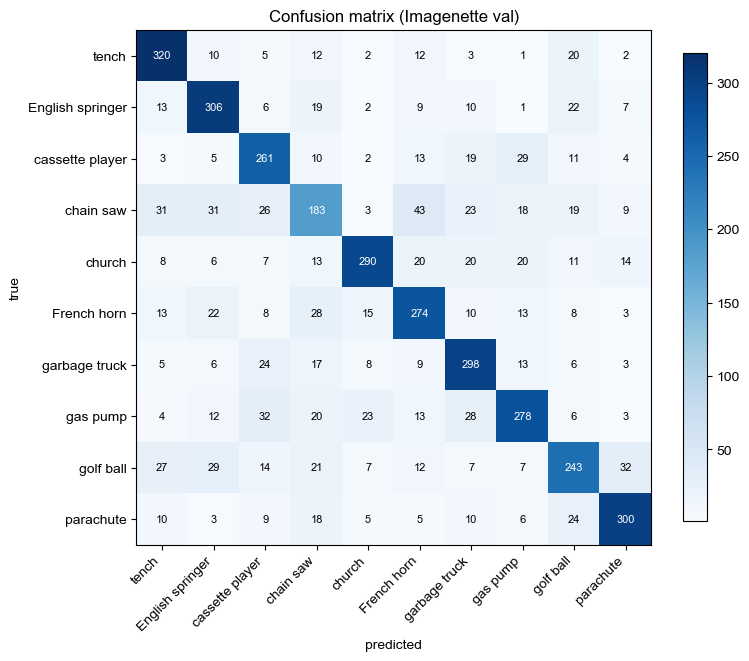

最常混淆：
           chain saw 被判成 French horn       43 次
           golf ball 被判成 parachute         32 次
            gas pump 被判成 cassette player   32 次
           chain saw 被判成 tench             31 次
           chain saw 被判成 English springer  31 次


In [10]:
cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (Imagenette val)")
thr = cm.max() / 2
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > thr else "black")
fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout(); plt.show()

off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
print("最常混淆：")
for n, t, p in sorted(off, reverse=True)[:5]:
    print(f"  {t:>18} 被判成 {p:<18}{n} 次")

## 2.5 真的拿圖片來辨識

把驗證集的圖片丟進模型，印出 softmax 機率最高的類別。
綠色標題＝判對，紅色＝判錯（括號是正確答案）。

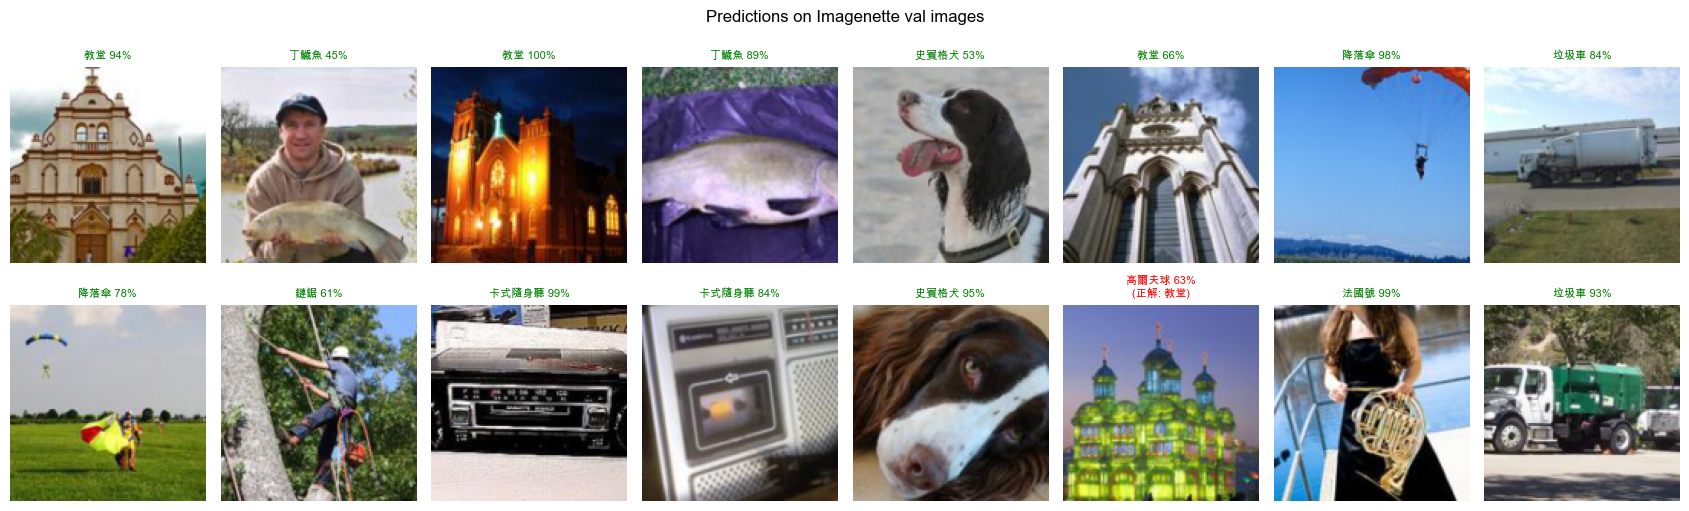

這 16 張：對 15 / 16


In [11]:
rng = np.random.RandomState(7)
idx = rng.choice(len(val_set), 16, replace=False)
imgs = torch.stack([val_set[i][0] for i in idx])
labs = np.array([val_set[i][1] for i in idx])

with torch.no_grad():
    prob = F.softmax(model(imgs.to(device)), dim=1).cpu().numpy()
pred = prob.argmax(1)

fig, axes = plt.subplots(2, 8, figsize=(17, 5.4))
for ax, img, p, t, pr in zip(axes.ravel(), imgs, pred, labs, prob):
    ax.imshow(denorm(img).permute(1, 2, 0).numpy())
    ok = p == t
    ax.set_title(f"{CLASSES_ZH[p]} {pr[p]*100:.0f}%" + ("" if ok else f"\n(正解: {CLASSES_ZH[t]})"),
                 fontsize=8, color="green" if ok else "red")
    ax.axis("off")
fig.suptitle("Predictions on Imagenette val images")
plt.tight_layout(); plt.show()

print(f"這 16 張：對 {(pred == labs).sum()} / 16")

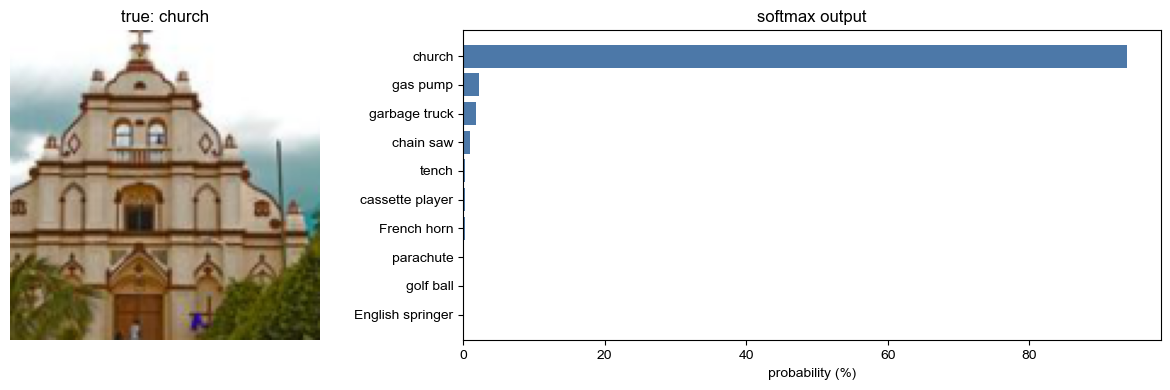

top-3:
  church            教堂           93.84%
  gas pump          加油槍           2.30%
  garbage truck     垃圾車           1.85%


In [12]:
# 單張圖的完整機率分佈（看模型在猶豫什麼）
k = int(idx[0])
img, true_lab = val_set[k]
with torch.no_grad():
    p = F.softmax(model(img.unsqueeze(0).to(device)), dim=1).cpu().numpy()[0]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
axa.imshow(denorm(img).permute(1, 2, 0).numpy()); axa.axis("off")
axa.set_title(f"true: {CLASSES[true_lab]}")
order = p.argsort()
axb.barh([CLASSES[i] for i in order], p[order] * 100, color="#4C78A8")
axb.set_xlabel("probability (%)"); axb.set_title("softmax output")
plt.tight_layout(); plt.show()

print("top-3:")
for i in p.argsort()[::-1][:3]:
    print(f"  {CLASSES[i]:<18}{CLASSES_ZH[i]:<12}{p[i]*100:6.2f}%")

## 2.6 卷積到底學到什麼

左邊是第一層 32 個 `3×3×3` filter 的權重（直接當 RGB 小圖畫出來），
右邊是同一張圖經過 `Conv1 + ReLU` 之後的 32 張 feature map。

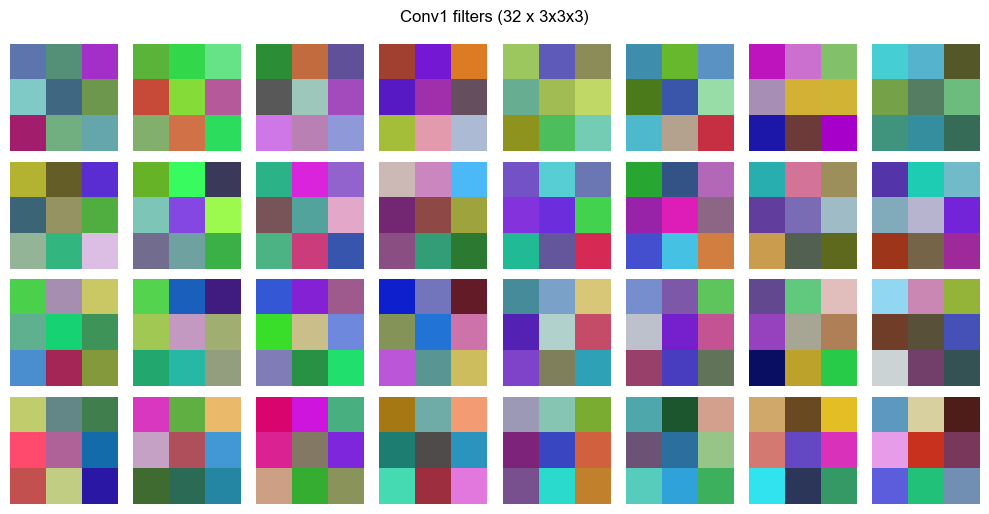

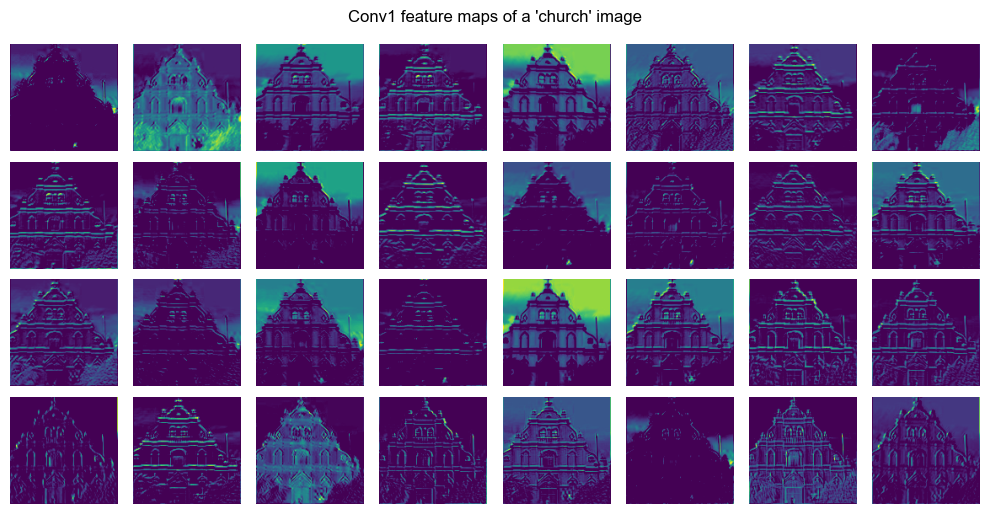

In [13]:
w = model.features[0].weight.detach().cpu()               # (32, 3, 3, 3)
w_show = (w - w.min()) / (w.max() - w.min())
fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for ax, f in zip(axes.ravel(), w_show):
    ax.imshow(f.permute(1, 2, 0).numpy()); ax.axis("off")
fig.suptitle("Conv1 filters (32 x 3x3x3)")
plt.tight_layout(); plt.show()

with torch.no_grad():
    fmap = model.features[:2](img.unsqueeze(0).to(device)).cpu()[0]   # Conv1+ReLU -> (32,128,128)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for ax, m in zip(axes.ravel(), fmap):
    ax.imshow(m.numpy(), cmap="viridis"); ax.axis("off")
fig.suptitle(f"Conv1 feature maps of a '{CLASSES[true_lab]}' image")
plt.tight_layout(); plt.show()

## 2.7 存模型 / 載回來 / 辨識任何一張本機圖片

存 `state_dict`（只存權重），順便把 class 名稱與前處理參數一起存進去，之後推論才不會對不上。

In [14]:
CKPT = "checkpoints/cnn_imagenette.pt"
torch.save({
    "state_dict": model.state_dict(),
    "classes": CLASSES, "classes_zh": CLASSES_ZH,
    "img_size": IMG_SIZE, "mean": MEAN, "std": STD,
    "val_acc": float((y_pred == y_true).mean()),
}, CKPT)
print("saved ->", CKPT)

ckpt = torch.load(CKPT, map_location=device, weights_only=False)
loaded = CNN_MLP(img_size=ckpt["img_size"], num_classes=len(ckpt["classes"])).to(device)
loaded.load_state_dict(ckpt["state_dict"])
loaded.eval()
print("recorded val acc :", f"{ckpt['val_acc']*100:.2f}%")
print("re-check val acc :", f"{evaluate(loaded, val_loader)[1]*100:.2f}%")

saved -> /Users/hsieh/Desktop/cnn_imagenette.pt
recorded val acc : 70.14%
re-check val acc : 70.14%


file : /Users/hsieh/Desktop/cnn_data/imagenette2-160/val/n03028079/n03028079_3081.JPEG
true : church 教堂 



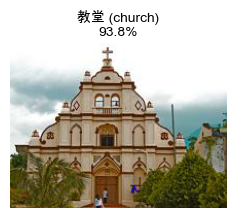

  church            教堂           93.84%
  gas pump          加油槍           2.30%
  garbage truck     垃圾車           1.85%


In [15]:
from PIL import Image

infer_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

@torch.no_grad()
def predict_image(path, net=None, topk=3, show=True):
    # 辨識任何一張本機圖片檔（jpg/png 都可以）
    net = net or loaded
    net.eval()
    pil = Image.open(path).convert("RGB")
    x = infer_tf(pil).unsqueeze(0).to(device)
    p = F.softmax(net(x), dim=1).cpu().numpy()[0]
    top = p.argsort()[::-1][:topk]
    if show:
        plt.figure(figsize=(2.8, 2.8)); plt.imshow(pil); plt.axis("off")
        plt.title(f"{CLASSES_ZH[top[0]]} ({CLASSES[top[0]]})\n{p[top[0]]*100:.1f}%", fontsize=10)
        plt.show()
    return [(CLASSES[i], CLASSES_ZH[i], float(p[i])) for i in top]


# 示範：從資料夾裡直接抓原始 jpg 檔（不經過 Dataset）來辨識
sample_path, sample_label = val_set._samples[k]
print("file :", sample_path)
print("true :", CLASSES[sample_label], CLASSES_ZH[sample_label], "\n")
for en, zh, pr in predict_image(sample_path):
    print(f"  {en:<18}{zh:<12}{pr*100:6.2f}%")

In [16]:
# 換成你自己的圖片路徑就能辨識（只有這 10 類，丟別的東西進去它一定會硬猜一個）
# for en, zh, pr in predict_image("my_photo.jpg"):
#     print(f"{en:<18}{zh:<12}{pr*100:6.2f}%")

---
## 小結

- 架構就是那一串：兩段 `Conv→ReLU→MaxPool` 抽特徵、`Flatten` 當交界、後面 MLP 做分類，
  輸出 logits 由 `CrossEntropyLoss` 內部做 softmax（所以 forward 裡不要自己加 softmax）。
- 參數分佈極度不平均：224 版本 98% 參數在 Flatten 後的第一層 Linear（5,138 萬）；
  128 版本是 65,536→256 共 1,677 萬，仍然佔全模型 99%。**瓶頸在 Flatten，不在卷積。**
- 只有兩層卷積、沒有 BatchNorm，這個模型在 Imagenette 驗證集大約落在 60～70%（隨機猜 10%）。
  訓練 acc 明顯高於驗證 acc = 過擬合，主因就是那層 1,677 萬參數的 Linear。
- 要再往上推的標準做法：
  1. 每個 Conv 後加 `BatchNorm2d` → 收斂更快更穩
  2. 堆到 3~4 段卷積，通道 32→64→128→256
  3. 用 `AdaptiveAvgPool2d(1)` 取代巨大的 Flatten → 參數少一到兩個數量級、過擬合大幅下降
  4. 加 `Dropout`、換 SGD+momentum 搭配更長的 cosine schedule
  5. 真的要高準確率就用 `torchvision.models.resnet18(weights=...)` 做 transfer learning